In [1]:
import geopandas as gpd
import osmnx as ox
import momepy as mp

/Users/clse/miniforge3/envs/orderbike/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
streets = gpd.read_file("../data/processed/ignored_files/paper/smrainet/idf_metro.gpkg")
streets = streets.loc[streets.geometry.type == "LineString"]
streets = streets.to_crs(streets.estimate_utm_crs())
G = mp.gdf_to_nx(streets, approach="primal", integer_labels=True)
for e in G.edges:
    G.edges[e]["length"] = G.edges[e]["geometry"].length

In [6]:
G.graph["crs"]

<Projected CRS: EPSG:32631>
Name: WGS 84 / UTM zone 31N
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Between 0°E and 6°E, northern hemisphere between equator and 84°N, onshore and offshore. Algeria. Andorra. Belgium. Benin. Burkina Faso. Denmark - North Sea. France. Germany - North Sea. Ghana. Luxembourg. Mali. Netherlands. Niger. Nigeria. Norway. Spain. Togo. United Kingdom (UK) - North Sea.
- bounds: (0.0, 0.0, 6.0, 84.0)
Coordinate Operation:
- name: UTM zone 31N
- method: Transverse Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [5]:
G.nodes[215]

{'x': 452480.9838509568, 'y': 5411786.83780963}

In [4]:
G.edges[28, 215, 0]

{'database_ref': None,
 'layer': 'metro',
 'database_org_id': '27371864',
 'mongo_dest_id': '5453b63455474a3362319751',
 'name': 'M1',
 'db_id': None,
 'database_dest_id': '27371862',
 'direction': None,
 'mongo_org_id': '5453b63455474a336231974f',
 'length': 419.84983436623367,
 'edge_type': None,
 'type': 'edge',
 'database_id': None,
 'degreeDual': 341.0,
 'geometry': <LINESTRING (452480.984 5411786.838, 452080.862 5411914.025)>,
 'mm_len': 419.84983436623367}

In [10]:
len(G), len(G.edges)

(303, 367)

In [4]:
gdf = gpd.read_file("../data/raw/idf_metro.gpkg")
gdf_nodes = gdf.loc[gdf.geometry.type == "Point"]
gdf_edges = gdf.loc[gdf.geometry.type == "LineString"]

In [43]:
xy = [point.xy for point in gdf_nodes.geometry]
gdf_nodes.loc[:, "x"] = [arr[0] for arr in xy]
gdf_nodes.loc[:, "y"] = [arr[1] for arr in xy]

/Users/clse/miniforge3/envs/orderbike/lib/python3.13/site-packages/geopandas/geodataframe.py:1968: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)
/Users/clse/miniforge3/envs/orderbike/lib/python3.13/site-packages/geopandas/geodataframe.py:1968: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)


In [5]:
G = mp.gdf_to_nx(
    gdf_edges.to_crs(gdf_edges.estimate_utm_crs()),
    approach="primal",
    integer_labels=True,
)

In [6]:
len(G)

303

In [7]:
len(G.edges)

367

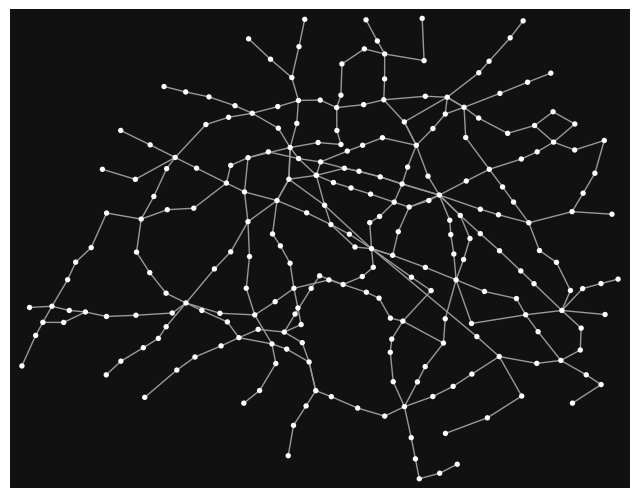

(<Figure size 800x800 with 1 Axes>, <Axes: >)

In [48]:
ox.plot_graph(G)